# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Andi Khaerunnisa Oddang
- **Email:** andi.khnisa@gmail.com
- **ID Dicoding:** (isi ID Dicoding kamu)

## Menentukan Pertanyaan Bisnis

Dataset ini berisi catatan penyewaan sepeda Capital Bikeshare (Washington D.C.) selama 2011-2012. Bayangkan kita adalah tim operasional yang harus memutuskan **kapan** menyiapkan sepeda dan **kapan** melakukan perawatan. Dua pertanyaan di bawah dirancang dengan metode SMART.

**Pertanyaan 1 (pola jam, data per jam)**
> Pada jam berapa rata-rata jumlah penyewaan sepeda mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011-2012, dan berapa persen total penyewaan yang terjadi pada tiap rentang waktu (dini hari, pagi, siang, sore, malam), sehingga tim operasional dapat menjadwalkan redistribusi sepeda?

**Pertanyaan 2 (pengaruh cuaca dan suhu, data per hari)**
> Seberapa besar penurunan rata-rata penyewaan harian pada hari bercuaca mist/berawan dan hujan/salju ringan dibandingkan hari cerah sepanjang 2011-2012, dan pada rentang suhu berapa rata-rata penyewaan harian paling tinggi, sehingga tim dapat menentukan waktu perawatan armada dan strategi promosi?

| Elemen SMART | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Fokus pada jam puncak, hari kerja vs akhir pekan | Fokus pada kategori cuaca dan rentang suhu |
| Measurable | Rata-rata penyewaan per jam dan persentase per rentang waktu | Persentase penurunan rata-rata penyewaan harian dan rata-rata per rentang suhu |
| Action-Oriented | Jadwal redistribusi sepeda dan penempatan petugas | Jadwal perawatan saat cuaca buruk, promosi saat cuaca/suhu ideal |
| Relevant | Ketersediaan sepeda di jam sibuk menentukan kepuasan pengguna | Cuaca adalah faktor eksternal terbesar yang memengaruhi permintaan |
| Time-bound | Periode 2011-2012 | Periode 2011-2012 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## Data Wrangling
### Gathering Data
Kita memakai dua berkas: `day.csv` (data harian, 731 baris) untuk Pertanyaan 2 dan `hour.csv` (data per jam, 17.379 baris) untuk Pertanyaan 1.

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("day_df  :", day_df.shape)
print("hour_df :", hour_df.shape)
day_df.head()

day_df  : (731, 16)
hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` punya 731 baris dan 16 kolom, `hour_df` punya 17.379 baris dan 17 kolom (tambahan kolom `hr`).
- Kolom kategori (`season`, `yr`, `weathersit`, dll.) masih berupa angka kode, dan kolom cuaca (`temp`, `atemp`, `hum`, `windspeed`) masih ternormalisasi sehingga belum mudah dibaca.

### Assessing Data

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {name} ===")
    df.info()
    print("Missing value  :", df.isna().sum().sum())
    print("Duplicate data :", df.duplicated().sum())
    print()

=== day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
Missing value  : 0
Duplicate data : 0

=== hour_df ===
<class 'pandas.DataFrame'>
RangeIndex:

In [5]:
day_df.describe().T[["min", "mean", "max"]]

,min,mean,max
instant,1.000000,366.000000,731.000000
season,1.000000,2.496580,4.000000
yr,0.000000,0.500684,1.000000
mnth,1.000000,6.519836,12.000000
holiday,0.000000,0.028728,1.000000
weekday,0.000000,2.997264,6.000000
workingday,0.000000,0.683995,1.000000
weathersit,1.000000,1.395349,3.000000
temp,0.059130,0.495385,0.861667
atemp,0.079070,0.474354,0.840896


In [6]:
# 1) Invalid value: kelembapan (hum) bernilai 0 itu tidak masuk akal secara fisik
print("hum == 0 di day_df :", (day_df["hum"] == 0).sum())
print("hum == 0 di hour_df:", (hour_df["hum"] == 0).sum())
print("Tanggal terkait    :", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

# 2) Inaccurate value: tipe data tanggal salah (string, seharusnya datetime)
print("\nTipe dteday:", day_df["dteday"].dtype)

# 3) Outlier: windspeed (IQR)
def count_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("\nOutlier windspeed (day_df) :", count_outlier(day_df["windspeed"]))
print("Outlier cnt (day_df)       :", count_outlier(day_df["cnt"]))

# 4) Windspeed = 0 pada data per jam (kemungkinan sensor tidak mencatat)
print("\nwindspeed == 0 di hour_df  :", (hour_df["windspeed"] == 0).sum(), "baris")

# 5) Kode cuaca 4 hampir tidak muncul
print("\nDistribusi weathersit hour_df:")
print(hour_df["weathersit"].value_counts().sort_index())

hum == 0 di day_df : 1
hum == 0 di hour_df: 22
Tanggal terkait    : <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str

Tipe dteday: str

Outlier windspeed (day_df) : 13
Outlier cnt (day_df)       : 0

windspeed == 0 di hour_df  : 2180 baris

Distribusi weathersit hour_df:
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


**Insight dan rencana pembersihan:**

| Temuan | Jenis masalah | Tindakan di tahap Cleaning |
|---|---|---|
| Tidak ada missing value dan duplikat | - | Tidak perlu tindakan |
| `hum` = 0 (1 baris di `day_df`, 22 baris di `hour_df`, semuanya tanggal 2011-03-10) | Invalid value | Ganti dengan median kelembapan bulan yang sama |
| `dteday` bertipe string | Inaccurate value (tipe data) | Ubah ke datetime |
| `season`, `yr`, `mnth`, `weekday`, `weathersit` berupa kode angka; `temp`, `atemp`, `hum`, `windspeed` ternormalisasi | Inconsistent / sulit dibaca | Buat label teks dan kembalikan skala asli (temp x 41, atemp x 50, hum x 100, windspeed x 67) |
| `windspeed` punya outlier (13 hari) dan banyak nilai 0 pada data per jam | Outlier | Dipertahankan karena angin kencang memang terjadi dan tidak memengaruhi pertanyaan bisnis; dicatat sebagai keterbatasan |

### Cleaning Data

In [7]:
season_map = {1: "Semi", 2: "Panas", 3: "Gugur", 4: "Dingin"}
weather_map = {1: "Cerah", 2: "Mist/Berawan", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

def clean(df):
    df = df.copy()
    # 1. tipe data tanggal
    df["dteday"] = pd.to_datetime(df["dteday"])

    # 2. invalid value hum = 0 -> median kelembapan valid pada bulan & tahun yang sama
    valid = df[df["hum"] > 0]
    median_hum = valid.groupby(["yr", "mnth"])["hum"].median()
    mask = df["hum"] == 0
    df.loc[mask, "hum"] = df.loc[mask].apply(lambda r: median_hum[(r["yr"], r["mnth"])], axis=1)

    # 3. kembalikan skala asli
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

    # 4. label kategori
    df["season_label"] = df["season"].map(season_map)
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["month_label"] = df["mnth"].map(month_map)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    return df

day_clean = clean(day_df)
hour_clean = clean(hour_df)

# Verifikasi
print("hum == 0 setelah cleaning:", (day_clean["hum"] == 0).sum(), (hour_clean["hum"] == 0).sum())
print("Tipe dteday:", day_clean["dteday"].dtype)
day_clean[["dteday", "season_label", "weather_label", "temp_c", "hum_pct", "windspeed_kmh", "cnt"]].head()

hum == 0 setelah cleaning: 0 0
Tipe dteday: datetime64[us]


,dteday,season_label,weather_label,temp_c,hum_pct,windspeed_kmh,cnt
0,2011-01-01,Semi,Mist/Berawan,14.110847,80.5833,10.749882,985
1,2011-01-02,Semi,Mist/Berawan,14.902598,69.6087,16.652113,801
2,2011-01-03,Semi,Cerah,8.050924,43.7273,16.636703,1349
3,2011-01-04,Semi,Cerah,8.200000,59.0435,10.739832,1562
4,2011-01-05,Semi,Cerah,9.305237,43.6957,12.522300,1600


**Insight:**
- Semua data kini bertipe benar dan berlabel, serta tidak ada lagi kelembapan 0.
- Outlier `windspeed` sengaja tidak dihapus karena merupakan kejadian cuaca nyata.

## Exploratory Data Analysis (EDA)
### Pertanyaan 1: Jam puncak penyewaan pada hari kerja vs akhir pekan/libur

In [8]:
hourly_pattern = (hour_clean.groupby(["day_type", "hr"])["cnt"].mean().round(1)
                  .unstack(0))
hourly_pattern.head(24)

day_type,Akhir Pekan/Libur,Hari Kerja
hr,,
0,90.8,36.8
1,69.5,16.6
2,53.2,8.7
3,25.8,4.9
4,8.3,5.4
5,8.7,24.9
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0


In [9]:
for tipe in hourly_pattern.columns:
    top3 = hourly_pattern[tipe].nlargest(3)
    print(f"{tipe}: jam puncak = {top3.index[0]}:00 ({top3.iloc[0]:.0f} sewa/jam). 3 teratas = {dict(top3.round(0))}")

Akhir Pekan/Libur: jam puncak = 13:00 (373 sewa/jam). 3 teratas = {13: np.float64(373.0), 12: np.float64(366.0), 14: np.float64(365.0)}
Hari Kerja: jam puncak = 17:00 (525 sewa/jam). 3 teratas = {17: np.float64(525.0), 18: np.float64(492.0), 8: np.float64(477.0)}


In [10]:
# Pengelompokan manual (binning) jam menjadi rentang waktu
bins = [-1, 5, 9, 15, 19, 23]
labels = ["Dini Hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"]
hour_clean["time_of_day"] = pd.cut(hour_clean["hr"], bins=bins, labels=labels)

tod = hour_clean.groupby(["day_type", "time_of_day"], observed=True)["cnt"].sum().unstack(0)
tod_pct = (tod / tod.sum() * 100).round(1)
tod_pct

day_type,Akhir Pekan/Libur,Hari Kerja
time_of_day,,
Dini Hari (00-05),5.9,2.1
Pagi (06-09),7.8,24.1
Siang (10-15),47.0,23.4
Sore (16-19),27.4,36.1
Malam (20-23),11.9,14.4


In [11]:
user_split = hour_clean.groupby("day_type")[["casual", "registered"]].sum()
user_split["pct_registered"] = (user_split["registered"] / (user_split["casual"] + user_split["registered"]) * 100).round(1)
user_split

,casual,registered,pct_registered
day_type,,,
Akhir Pekan/Libur,316732,683537,68.3
Hari Kerja,303285,1989125,86.8


**Insight:**
- Hari kerja punya **dua puncak**: pukul **08:00** (rata-rata sekitar 477 sewa) dan puncak tertinggi pukul **17:00** (sekitar 525 sewa), pola khas jam berangkat dan pulang kerja.
- Akhir pekan/libur punya **satu puncak landai** pukul **13:00** (sekitar 373 sewa), dan sekitar 47% penyewaannya terjadi pada rentang siang (10-15).
- Pada hari kerja, rentang sore (16-19) menyumbang sekitar 36% dan pagi (06-09) sekitar 24% dari total penyewaan.
- Pengguna terdaftar mendominasi pada hari kerja (sekitar 87%), sedangkan pada akhir pekan porsi pengguna kasual lebih besar (sekitar 32%).

### Pertanyaan 2: Pengaruh cuaca dan suhu terhadap penyewaan harian

In [12]:
weather_stats = (day_clean.groupby("weather_label")["cnt"]
                 .agg(jumlah_hari="count", rata_rata="mean").round(0))
weather_stats = weather_stats.loc[["Cerah", "Mist/Berawan", "Hujan/Salju Ringan"]]
baseline = weather_stats.loc["Cerah", "rata_rata"]
weather_stats["penurunan_vs_cerah_%"] = ((1 - weather_stats["rata_rata"] / baseline) * 100).round(1)
weather_stats

,jumlah_hari,rata_rata,penurunan_vs_cerah_%
weather_label,,,
Cerah,463,4877.0,0.0
Mist/Berawan,247,4036.0,17.2
Hujan/Salju Ringan,21,1803.0,63.0


In [13]:
season_stats = day_clean.groupby("season_label")["cnt"].mean().round(0).reindex(["Semi", "Panas", "Gugur", "Dingin"])
season_stats

season_label
Semi      2604.0
Panas     4992.0
Gugur     5644.0
Dingin    4728.0
Name: cnt, dtype: float64

In [14]:
# Pengelompokan manual (binning) suhu aktual (derajat Celsius)
temp_bins = [0, 10, 20, 30, 50]
temp_labels = ["< 10 C", "10-20 C", "20-30 C", "> 30 C"]
day_clean["temp_bin"] = pd.cut(day_clean["temp_c"], bins=temp_bins, labels=temp_labels)

temp_stats = day_clean.groupby("temp_bin", observed=True)["cnt"].agg(jumlah_hari="count", rata_rata="mean").round(0)
temp_stats

,jumlah_hari,rata_rata
temp_bin,,
< 10 C,60,1678.0
10-20 C,299,3692.0
20-30 C,300,5662.0
> 30 C,72,5410.0


**Insight:**
- Dibanding hari cerah (rata-rata sekitar 4.877 sewa/hari), hari **mist/berawan turun sekitar 17%** dan hari **hujan/salju ringan turun sekitar 63%** (hanya sekitar 1.803 sewa/hari).
- Musim gugur punya rata-rata tertinggi (sekitar 5.644), sedangkan musim semi terendah (sekitar 2.604).
- Penyewaan paling tinggi pada suhu **20-30 C** (sekitar 5.662/hari); di atas 30 C sedikit turun (sekitar 5.410), dan di bawah 10 C jauh lebih rendah (sekitar 1.678).
- Perlu diingat: hanya 21 hari bercuaca hujan/salju ringan sehingga estimasinya kurang stabil, dan tidak ada hari cuaca 4 di data harian.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa penyewaan memuncak?

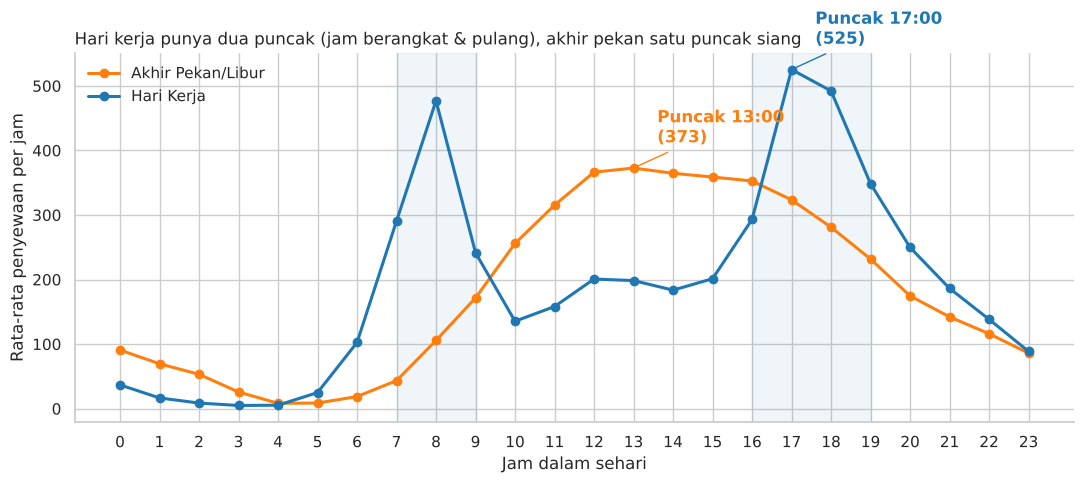

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = {"Hari Kerja": "#1f77b4", "Akhir Pekan/Libur": "#ff7f0e"}

for tipe in hourly_pattern.columns:
    ax.plot(hourly_pattern.index, hourly_pattern[tipe], marker="o", linewidth=2.2,
            color=colors[tipe], label=tipe)
    peak_hr = hourly_pattern[tipe].idxmax()
    peak_val = hourly_pattern[tipe].max()
    ax.annotate(f"Puncak {peak_hr}:00\n({peak_val:.0f})", xy=(peak_hr, peak_val),
                xytext=(peak_hr + 0.6, peak_val + 40), color=colors[tipe], fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=colors[tipe]))

ax.axvspan(7, 9, color="#1f77b4", alpha=0.07)
ax.axvspan(16, 19, color="#1f77b4", alpha=0.07)
ax.set_xticks(range(0, 24))
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_title("Hari kerja punya dua puncak (jam berangkat & pulang), akhir pekan satu puncak siang",
             fontsize=12, loc="left")
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

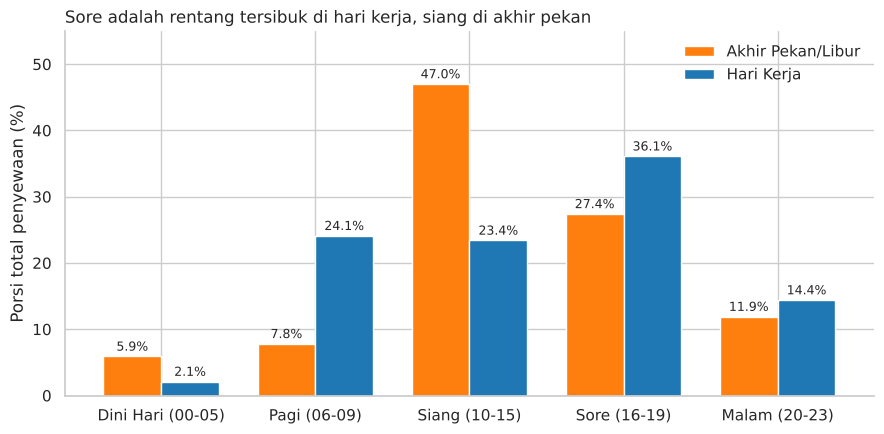

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
tod_pct.plot(kind="bar", ax=ax, color=[colors["Akhir Pekan/Libur"], colors["Hari Kerja"]], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)
ax.set_xlabel("")
ax.set_ylabel("Porsi total penyewaan (%)")
ax.set_title("Sore adalah rentang tersibuk di hari kerja, siang di akhir pekan", fontsize=12, loc="left")
ax.set_ylim(0, 55)
plt.xticks(rotation=0)
ax.legend(title="", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan:** Garis biru (hari kerja) naik tajam pukul 07-08 dan 17-18, menandakan komuter. Garis oranye (akhir pekan/libur) naik pelan dan memuncak pukul 13:00, menandakan penyewaan rekreasi. Diagram batang menegaskan bahwa 36% penyewaan hari kerja terjadi pada rentang 16-19, sedangkan 47% penyewaan akhir pekan terjadi pada rentang 10-15.

### Pertanyaan 2: Seberapa besar pengaruh cuaca dan suhu?

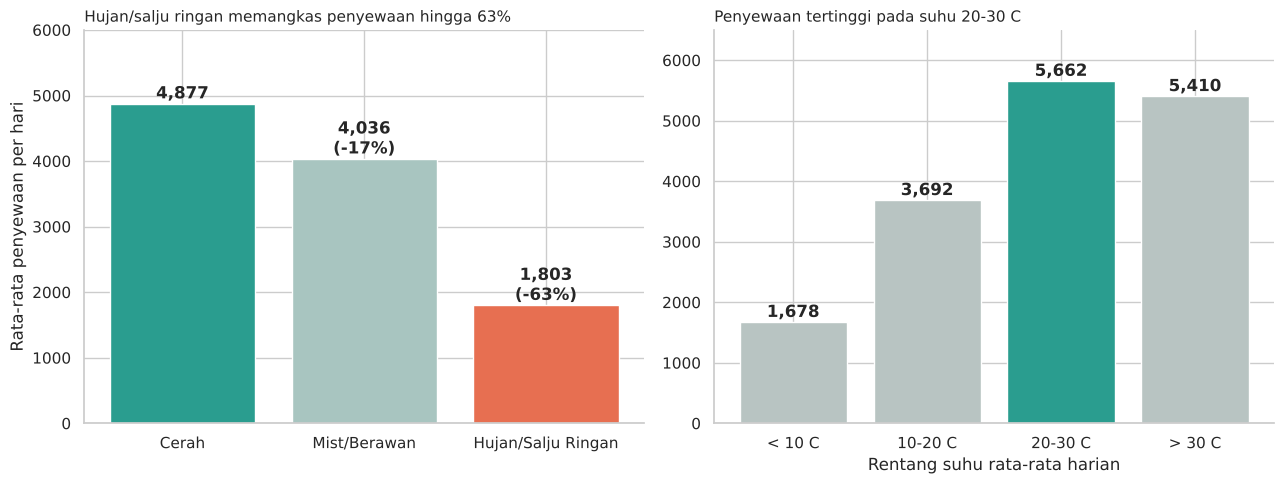

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Cuaca
order = ["Cerah", "Mist/Berawan", "Hujan/Salju Ringan"]
vals = weather_stats.loc[order, "rata_rata"]
bar_colors = ["#2a9d8f", "#a8c5c0", "#e76f51"]
axes[0].bar(order, vals, color=bar_colors)
for i, (o, v) in enumerate(vals.items()):
    drop = weather_stats.loc[o, "penurunan_vs_cerah_%"]
    label = f"{v:,.0f}" if drop == 0 else f"{v:,.0f}\n(-{drop:.0f}%)"
    axes[0].text(i, v + 80, label, ha="center", fontweight="bold")
axes[0].set_ylim(0, 6000)
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_title("Hujan/salju ringan memangkas penyewaan hingga 63%", fontsize=11, loc="left")

# (b) Suhu
tvals = temp_stats["rata_rata"]
top = tvals.idxmax()
tcolors = ["#2a9d8f" if k == top else "#b8c4c2" for k in tvals.index]
axes[1].bar(tvals.index.astype(str), tvals.values, color=tcolors)
for i, v in enumerate(tvals.values):
    axes[1].text(i, v + 80, f"{v:,.0f}", ha="center", fontweight="bold")
axes[1].set_ylim(0, 6500)
axes[1].set_xlabel("Rentang suhu rata-rata harian")
axes[1].set_title("Penyewaan tertinggi pada suhu 20-30 C", fontsize=11, loc="left")

sns.despine()
plt.tight_layout()
plt.show()

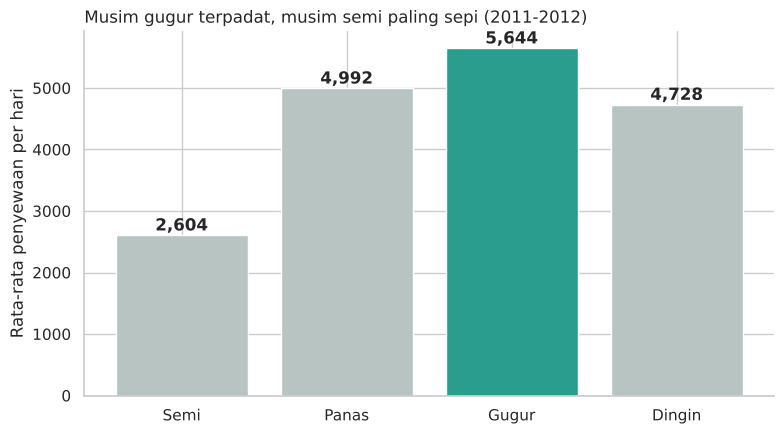

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sv = season_stats
ax.bar(sv.index, sv.values, color=["#b8c4c2", "#b8c4c2", "#2a9d8f", "#b8c4c2"])
for i, v in enumerate(sv.values):
    ax.text(i, v + 80, f"{v:,.0f}", ha="center", fontweight="bold")
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_title("Musim gugur terpadat, musim semi paling sepi (2011-2012)", fontsize=12, loc="left")
sns.despine()
plt.tight_layout()
plt.show()

**Penjelasan:** Warna hijau menandai kategori terbaik, merah menandai kondisi terburuk. Penyewaan menurun bertahap seiring memburuknya cuaca, dan paling tinggi pada suhu nyaman 20-30 C.

## Analisis Lanjutan (Opsional): Manual Grouping Tingkat Permintaan
**Tujuan:** Mengelompokkan hari ke dalam tiga tingkat permintaan menggunakan aturan bisnis (tanpa algoritma machine learning), lalu melihat komposisinya pada tiap kondisi cuaca. Aturan: **Rendah** (< 3.000 sewa/hari), **Sedang** (3.000-6.000), **Tinggi** (> 6.000). Teknik ini (manual grouping dan binning) membantu operator menyederhanakan angka harian menjadi kategori yang mudah dipakai untuk perencanaan.

In [19]:
day_clean["demand_level"] = pd.cut(day_clean["cnt"], bins=[0, 3000, 6000, 10000],
                                   labels=["Rendah", "Sedang", "Tinggi"])

demand_by_weather = (pd.crosstab(day_clean["weather_label"], day_clean["demand_level"], normalize="index") * 100).round(1)
demand_by_weather = demand_by_weather.loc[["Cerah", "Mist/Berawan", "Hujan/Salju Ringan"]]
print(day_clean["demand_level"].value_counts().reindex(["Rendah", "Sedang", "Tinggi"]))
demand_by_weather

demand_level
Rendah    172
Sedang    379
Tinggi    180
Name: count, dtype: int64


demand_level,Rendah,Sedang,Tinggi
weather_label,,,
Cerah,16.8,52.9,30.2
Mist/Berawan,30.4,53.4,16.2
Hujan/Salju Ringan,90.5,9.5,0.0


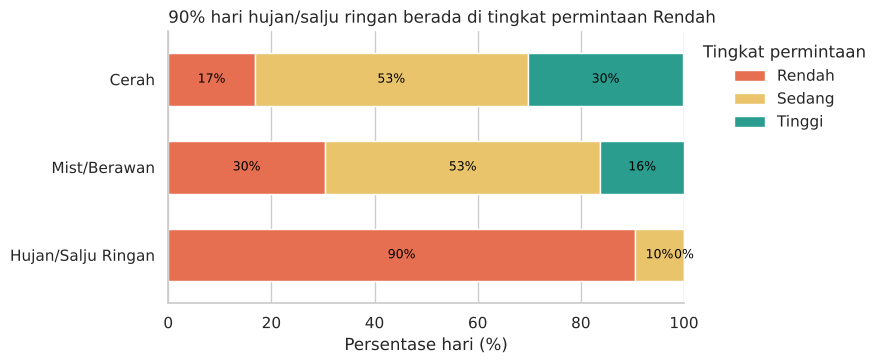

In [20]:
ax = demand_by_weather.plot(kind="barh", stacked=True, figsize=(9, 3.8),
                            color=["#e76f51", "#e9c46a", "#2a9d8f"], width=0.6)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", label_type="center", fontsize=9, color="black")
ax.set_xlabel("Persentase hari (%)")
ax.set_ylabel("")
ax.set_title("90% hari hujan/salju ringan berada di tingkat permintaan Rendah", fontsize=12, loc="left")
ax.legend(title="Tingkat permintaan", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.invert_yaxis()
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** Pada hari cerah, sekitar 30% hari masuk kategori Tinggi dan hanya 17% Rendah. Pada hari hujan/salju ringan, sekitar 90% hari masuk kategori Rendah dan tidak ada satu pun hari Tinggi. Pengelompokan ini mengonfirmasi bahwa prakiraan cuaca bisa dipakai sebagai sinyal awal perencanaan armada.

## Conclusion

**Kesimpulan Pertanyaan 1 (jam puncak):**
- Pada hari kerja, penyewaan memuncak pukul **17:00** (sekitar 525 sewa/jam) dengan puncak kedua pukul **08:00** (sekitar 477 sewa/jam). Rentang sore (16-19) menyumbang sekitar 36% dan pagi (06-09) sekitar 24% total penyewaan hari kerja.
- Pada akhir pekan/libur, puncaknya hanya satu, yaitu pukul **13:00** (sekitar 373 sewa/jam), dengan sekitar 47% penyewaan terjadi pada rentang siang (10-15).

**Kesimpulan Pertanyaan 2 (cuaca dan suhu):**
- Dibanding hari cerah, penyewaan harian turun sekitar **17%** pada hari mist/berawan dan sekitar **63%** pada hari hujan/salju ringan.
- Rata-rata penyewaan harian tertinggi terjadi pada suhu **20-30 C** (sekitar 5.662), sedangkan di bawah 10 C hanya sekitar 1.678. Musim gugur adalah musim tersibuk.

## Rekomendasi (Action Item)
1. **Redistribusi sepeda hari kerja:** selesaikan pengisian ulang stasiun sebelum pukul 07:00 (ke area perumahan) dan sebelum 16:00 (ke area perkantoran dan transit), karena kedua rentang itu menyumbang sekitar 60% penyewaan hari kerja.
2. **Jadwal akhir pekan:** siapkan stok lebih banyak di area rekreasi pada pukul 10:00-15:00 dan tawarkan promo untuk pengguna kasual pada rentang ini.
3. **Perawatan terjadwal:** jadwalkan servis armada pada hari dengan prakiraan hujan/salju atau suhu di bawah 10 C, karena permintaan diperkirakan turun lebih dari 60%.
4. **Promosi musiman:** fokuskan kampanye dan penambahan armada pada musim panas hingga gugur (suhu 20-30 C), dan beri insentif keanggotaan pada musim semi saat permintaan paling rendah.

*Keterbatasan:* hanya 21 hari cuaca hujan/salju ringan dan tidak ada hari cuaca ekstrem di data harian, sehingga estimasi untuk kondisi tersebut kurang stabil. Analisis ini bersifat deskriptif, bukan sebab-akibat.

## Menyimpan Data untuk Dashboard

In [21]:
day_clean.to_csv("dashboard/day_data.csv", index=False)
hour_clean.to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan:", day_clean.shape, hour_clean.shape)

Tersimpan: (731, 28) (17379, 28)
